In [1]:
# =============================================================================
# PART 1: IMPORTS AND DATA PREPARATION
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
import pmdarima as pm
from pmdarima.preprocessing import FourierFeaturizer
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:
# =============================================================================
# UCM MODEL - PART 1: SETUP
# =============================================================================

# Additional imports for UCM
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.graphics.tsaplots import plot_predict
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("UNOBSERVED COMPONENTS MODEL (UCM)")
print("=" * 60)
print("\nUCM explicitly models:")
print("  - Level (base pedestrian count)")
print("  - Seasonal components (24h daily, 168h weekly)")
print("  - Irregular (random noise)")
print("=" * 60)

UNOBSERVED COMPONENTS MODEL (UCM)

UCM explicitly models:
  - Level (base pedestrian count)
  - Seasonal components (24h daily, 168h weekly)
  - Irregular (random noise)


In [3]:
# =============================================================================
# LOAD DATA
# =============================================================================

# Load dataset 
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df = df.rename(columns={'time': 'date'})

# Ensure 'date' is datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Dataset shape: (42767, 1)
Date range: 2015-04-15 00:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-04-15 00:00:01   13.0
2015-04-15 01:00:01    2.0
2015-04-15 02:00:01    5.0
2015-04-15 03:00:01    3.0
2015-04-15 04:00:01    8.0


In [4]:
# =============================================================================
# Reduce dataset size for computational efficiency
# =============================================================================

# Percentage of data to KEEP (from the end of the dataset)
# Change this value to adjust the reduction (e.g. 0.5 = 50%, 0.2 = 20%)
KEEP_PERCENTAGE = 0.6

cutoff_index = int(len(df) * (1 - KEEP_PERCENTAGE))
df = df.iloc[cutoff_index:]

print(f"Kept last {KEEP_PERCENTAGE*100}% of data")
print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Kept last 60.0% of data
Dataset shape: (25661, 1)
Date range: 2017-03-27 18:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2017-03-27 18:00:01  364.0
2017-03-27 19:00:01  286.0
2017-03-27 20:00:01  193.0
2017-03-27 21:00:01  120.0
2017-03-27 22:00:01  106.0


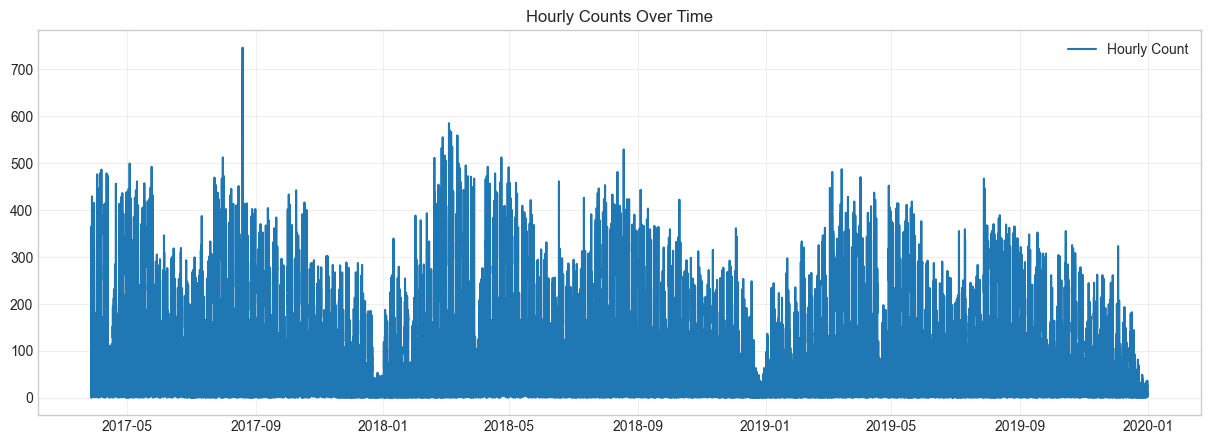

In [5]:
# Plot the dataset
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], label='Hourly Count', color='#1f77b4')
plt.title('Hourly Counts Over Time')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [6]:
# =============================================================================
# PART 2: TRAIN / VALIDATION / TEST SPLIT
# =============================================================================

# Define split sizes
FORECAST_HORIZON = 1440  # 60 days * 24 hours

# Identify where the actual values end (before missing values)
# Based on your info: training data ends Dec 31, 2019
# The missing 1440 values are AFTER this date

# Split the data that HAS values
df_with_values = df[df['value'].notna()].copy()

print(f"Data with values: {len(df_with_values)} observations")
print(f"Date range with values: {df_with_values.index.min()} to {df_with_values.index.max()}")

# Create splits
# Test set: We don't have values yet (the 1440 missing ones) - we'll forecast these
# Validation set: Last 1440 observations WITH values (for hyperparameter tuning)
# Training set: Everything before validation

train_end_idx = len(df_with_values) - FORECAST_HORIZON
val_end_idx = len(df_with_values)

train = df_with_values.iloc[:train_end_idx].copy()
validation = df_with_values.iloc[train_end_idx:val_end_idx].copy()

print(f"\n{'='*60}")
print(f"SPLIT SUMMARY")
print(f"{'='*60}")
print(f"Training set:   {len(train):,} obs | {train.index.min()} to {train.index.max()}")
print(f"Validation set: {len(validation):,} obs | {validation.index.min()} to {validation.index.max()}")
print(f"Test set:       {FORECAST_HORIZON:,} obs | To be forecasted (Jan-Feb 2020)")
print(f"{'='*60}")

# Extract the series
y_train = train['value']
y_val = validation['value']

Data with values: 24222 observations
Date range with values: 2017-03-27 18:00:01 to 2019-12-31 23:00:01

SPLIT SUMMARY
Training set:   22,782 obs | 2017-03-27 18:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01
Test set:       1,440 obs | To be forecasted (Jan-Feb 2020)


In [7]:
# =============================================================================
# PART 2a: BOX-COX TRANSFORMATION
# =============================================================================
from scipy.stats import boxcox
from scipy.special import inv_boxcox

print(f"Applying Box-Cox Transformation to stabilize variance...")

# 1. Handle non-positive values
# Box-Cox requires strictly positive data (> 0). 
# If we have 0 or negative values, we add an offset constant.
if y_train.min() <= 0:
    # Add offset so the minimum value becomes 1.0
    # For count data with zeros, usually adding 1 is sufficient
    offset = 1.0 - y_train.min()
    print(f"Data contains non-positive values (min: {y_train.min()}).")
    print(f"Adding offset of {offset} to all data before transformation.")
else:
    offset = 0.0

# 2. Apply Box-Cox on training data
# This finds the optimal lambda that maximizes log-likelihood
y_train_shifted = y_train + offset
y_train_transformed, lam = boxcox(y_train_shifted)

# Store original y_train just in case
y_train_original = y_train.copy()

# Update y_train with transformed values for the model
y_train = pd.Series(y_train_transformed, index=y_train.index)

print(f"\nOptimal Lambda found: {lam:.4f}")
if np.isclose(lam, 0, atol=0.05):
    print("Lambda is close to 0, which corresponds to Log Transformation.")
elif np.isclose(lam, 1, atol=0.05):
    print("Lambda is close to 1, implying limited need for transformation.")
    
print(f"Transformed Training Data Range: {y_train.min():.4f} to {y_train.max():.4f}")

# 3. Define helper for inverse transformation (for predictions)
def inverse_boxcox(y_transformed, lambda_, offset_):
    """
    Inverse Box-Cox transformation to get back to original scale.
    """
    y_inv = inv_boxcox(y_transformed, lambda_)
    return y_inv - offset_

print("\nNOTE: y_train is now transformed.")
print("The model will be trained on the Box-Cox transformed data.")
print("We must inverse-transform predictions using 'inverse_boxcox' to compare with actuals.")

Applying Box-Cox Transformation to stabilize variance...
Data contains non-positive values (min: 0.0).
Adding offset of 1.0 to all data before transformation.

Optimal Lambda found: 0.2567
Transformed Training Data Range: 0.0000 to 17.3917

NOTE: y_train is now transformed.
The model will be trained on the Box-Cox transformed data.
We must inverse-transform predictions using 'inverse_boxcox' to compare with actuals.


In [8]:
# We'll use the SAME train/validation split as SARIMA
# These should already be defined from SARIMA code
print(f"\nUsing existing split:")
print(f"Training set:   {len(train):,} obs | {train.index.min()} to {train.index.max()}")
print(f"Validation set: {len(validation):,} obs | {validation.index.min()} to {validation.index.max()}")


Using existing split:
Training set:   22,782 obs | 2017-03-27 18:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01


In [9]:
# =============================================================================
# UCM MODEL - PART 3: MODEL SPECIFICATION SEARCH
# =============================================================================

# Define candidate UCM specifications
# We'll test different combinations of components

ucm_specs = [
    {
        'name': 'UCM-1: Local Level + Seasonal(24h + 168h)',
        'level': 'local level',
        'trend': False,
        'seasonal': [24, 168],  # Both daily and weekly
        'freq_seasonal': None,
        'cycle': False,
        'autoregressive': 0,
        'irregular': True
    },
    {
        'name': 'UCM-2: Local Level + Freq Seasonal',
        'level': 'local level',
        'trend': False,
        'seasonal': None,
        'freq_seasonal': [{'period': 24, 'harmonics': 4}, 
                          {'period': 168, 'harmonics': 3}],
        'cycle': False,
        'autoregressive': 0,
        'irregular': True
    },
    {
        'name': 'UCM-3: Local Level + Seasonal(24h) + AR(1)',
        'level': 'local level',
        'trend': False,
        'seasonal': 24,
        'freq_seasonal': [{'period': 168, 'harmonics': 3}],
        'cycle': False,
        'autoregressive': 1,
        'irregular': True
    },
    {
        'name': 'UCM-4: Local Level Trend + Seasonal',
        'level': 'local linear trend',
        'trend': True,
        'seasonal': [24, 168],
        'freq_seasonal': None,
        'cycle': False,
        'autoregressive': 0,
        'irregular': True
    },
]

print("\nTesting UCM model specifications...")
print("=" * 80)

ucm_results = []

for i, spec in enumerate(ucm_specs, 1):
    try:
        print(f"\n[{i}/{len(ucm_specs)}] {spec['name']}")
        print("-" * 80)
        
        # Build model specification
        model = UnobservedComponents(
            y_train,
            level=spec['level'],
            trend=spec['trend'],
            seasonal=spec['seasonal'],
            freq_seasonal=spec['freq_seasonal'],
            cycle=spec['cycle'],
            autoregressive=spec['autoregressive'],
            irregular=spec['irregular']
        )
        
        # Fit model
        print("   Fitting model...", end=' ')
        model_fit = model.fit(disp=False, maxiter=200)
        
        # Store results
        aic = model_fit.aic
        bic = model_fit.bic
        llf = model_fit.llf
        
        ucm_results.append({
            'name': spec['name'],
            'spec': spec,
            'model': model_fit,
            'aic': aic,
            'bic': bic,
            'llf': llf
        })
        
        print(f"✓")
        print(f"   AIC: {aic:,.2f} | BIC: {bic:,.2f} | LogLik: {llf:,.2f}")
        
    except Exception as e:
        print(f"✗ Failed: {str(e)[:60]}")
        continue

# Compare models
print("\n" + "=" * 80)
print("UCM MODEL COMPARISON")
print("=" * 80)

comparison_df = pd.DataFrame([
    {
        'Model': r['name'],
        'AIC': r['aic'],
        'BIC': r['bic'],
        'LogLikelihood': r['llf']
    }
    for r in ucm_results
]).sort_values('AIC')

print(comparison_df.to_string(index=False))
print("=" * 80)

# Select best model by AIC
best_ucm = min(ucm_results, key=lambda x: x['aic'])
best_ucm_model = best_ucm['model']
best_ucm_name = best_ucm['name']

print(f"\n🏆 BEST MODEL: {best_ucm_name}")
print(f"   AIC: {best_ucm['aic']:,.2f}")
print(f"   BIC: {best_ucm['bic']:,.2f}")


Testing UCM model specifications...

[1/4] UCM-1: Local Level + Seasonal(24h + 168h)
--------------------------------------------------------------------------------
✗ Failed: '>' not supported between instances of 'list' and 'int'

[2/4] UCM-2: Local Level + Freq Seasonal
--------------------------------------------------------------------------------
   Fitting model... ✓
   AIC: 67,893.32 | BIC: 67,925.46 | LogLik: -33,942.66

[3/4] UCM-3: Local Level + Seasonal(24h) + AR(1)
--------------------------------------------------------------------------------
   Fitting model... ✓
   AIC: 62,619.66 | BIC: 62,667.85 | LogLik: -31,303.83

[4/4] UCM-4: Local Level Trend + Seasonal
--------------------------------------------------------------------------------
✗ Failed: '>' not supported between instances of 'list' and 'int'

UCM MODEL COMPARISON
                                     Model          AIC          BIC  LogLikelihood
UCM-3: Local Level + Seasonal(24h) + AR(1) 62619.658467 62667

In [10]:
# =============================================================================
# UCM MODEL - PART 4: BEST MODEL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("BEST UCM MODEL SUMMARY")
print("=" * 80)
print(best_ucm_model.summary())

# Extract model components
print("\n" + "=" * 80)
print("MODEL COMPONENTS")
print("=" * 80)

# Check which components are in the model
if hasattr(best_ucm_model, 'level'):
    print("✓ Level component included")
if hasattr(best_ucm_model, 'trend'):
    print("✓ Trend component included")
if hasattr(best_ucm_model, 'seasonal'):
    print("✓ Seasonal component included")

# Parameter estimates
print("\nParameter Estimates:")
print(best_ucm_model.params)


BEST UCM MODEL SUMMARY
                                Unobserved Components Results                                 
Dep. Variable:                                      y   No. Observations:                22782
Model:                                    local level   Log Likelihood              -31303.829
                            + stochastic seasonal(24)   AIC                          62619.658
                   + stochastic freq_seasonal(168(3))   BIC                          62667.853
                                              + AR(1)   HQIC                         62635.328
Date:                                Thu, 05 Feb 2026                                         
Time:                                        19:45:07                                         
Sample:                                    03-27-2017                                         
                                         - 11-01-2019                                         
Covariance Type:          

In [11]:
# =============================================================================
# METRICS FUNCTION
# =============================================================================

def calculate_metrics(actual, forecast, name="Model"):
    """
    Calculates common time series metrics: RMSE, MAE, and MAPE.
    Handles division by zero for MAPE by initializing with valid non-zero actuals.
    """
    # Ensure inputs are numpy arrays for easier math
    y_true = np.array(actual)
    y_pred = np.array(forecast)
    
    # 1. RMSE (Root Mean Squared Error)
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    
    # 2. MAE (Mean Absolute Error)
    mae = np.mean(np.abs(y_true - y_pred))
    
    # 3. MAPE (Mean Absolute Percentage Error) - Non-zero
    # We filter out instances where actual is 0 to avoid division by zero errors
    mask = y_true != 0
    if np.sum(mask) > 0:
        mape_nonzero = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    else:
        mape_nonzero = np.nan
        
    metrics = {
        'name': name,
        'rmse': rmse,
        'mae': mae,
        'mape_nonzero': mape_nonzero
    }
    
    # Optional: Print metrics immediately
    print(f"Metrics for {name}:")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"MAPE: {mape_nonzero:.2f}%")
    
    return metrics


In [12]:
# =============================================================================
# UCM MODEL - PART 5: VALIDATION FORECAST
# =============================================================================

print("\n" + "=" * 80)
print("GENERATING VALIDATION FORECAST")
print("=" * 80)

# Generate forecast for validation period
ucm_forecast = best_ucm_model.forecast(steps=FORECAST_HORIZON)

# INVERSE BOX-COX TRANSFORM IF APPLIED
if 'lam' in locals() and 'offset' in locals():
    print(f"Inverse transforming validation forecast using lambda={lam:.4f}")
    ucm_forecast = inverse_boxcox(ucm_forecast, lam, offset)

# Create forecast DataFrame
ucm_val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': ucm_forecast.values,
    'date': y_val.index
}).set_index('date')

# Clip negative forecasts to 0
ucm_val_forecast_df['forecast'] = ucm_val_forecast_df['forecast'].clip(lower=0)

# Calculate metrics
def calculate_metrics(actual, predicted, name=""):
    """Calculate and print forecast metrics."""
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    # Handle MAPE for zero values
    mask = actual > 0
    mape_nonzero = mean_absolute_percentage_error(actual[mask], predicted[mask]) * 100
    
    print(f"\n{'='*50}")
    print(f"METRICS {name}")
    print(f"{'='*50}")
    print(f"RMSE:  {rmse:.2f}")
    print(f"MAE:   {mae:.2f}")
    print(f"MAPE:  {mape:.2f}% (all data)")
    print(f"MAPE:  {mape_nonzero:.2f}% (excluding zeros)")
    print(f"{'='*50}")
    
    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_nonzero': mape_nonzero}

ucm_metrics = calculate_metrics(
    ucm_val_forecast_df['actual'], 
    ucm_val_forecast_df['forecast'],
    name="UCM VALIDATION"
)


GENERATING VALIDATION FORECAST
Inverse transforming validation forecast using lambda=0.2567

METRICS UCM VALIDATION
RMSE:  47.16
MAE:   31.11
MAPE:  67077574799258264.00% (all data)
MAPE:  154.74% (excluding zeros)


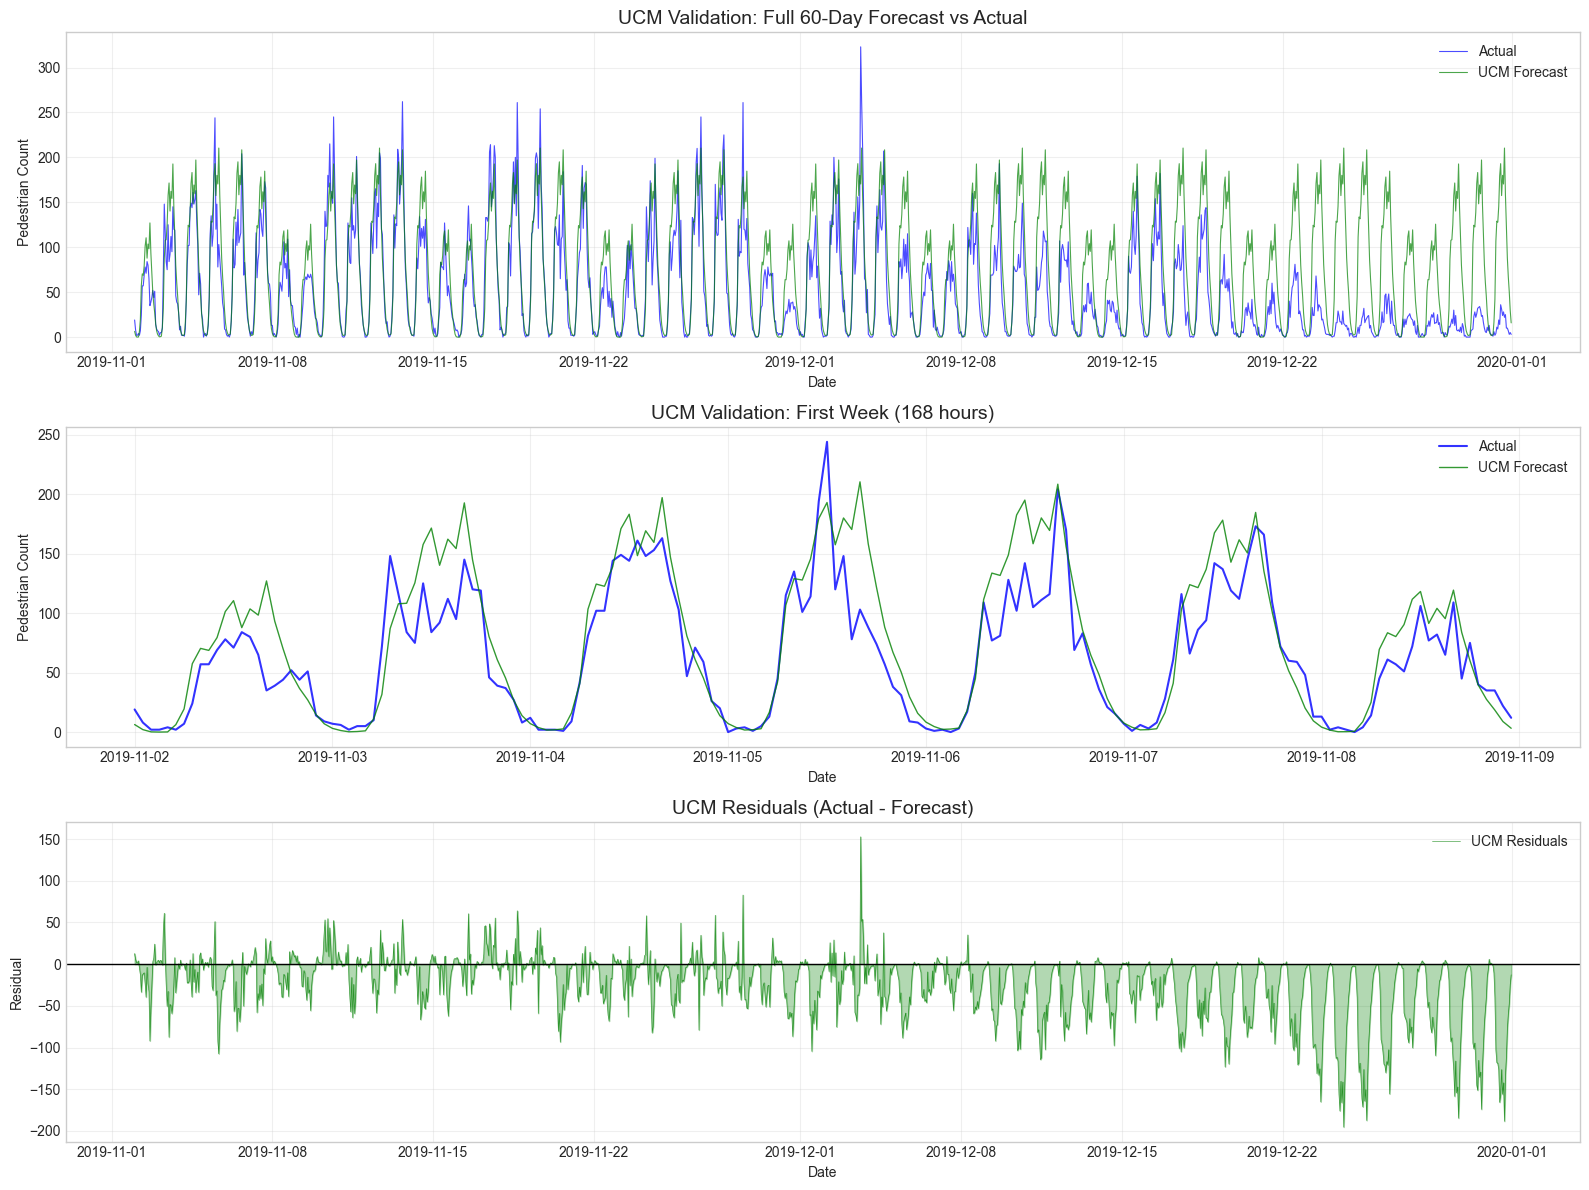

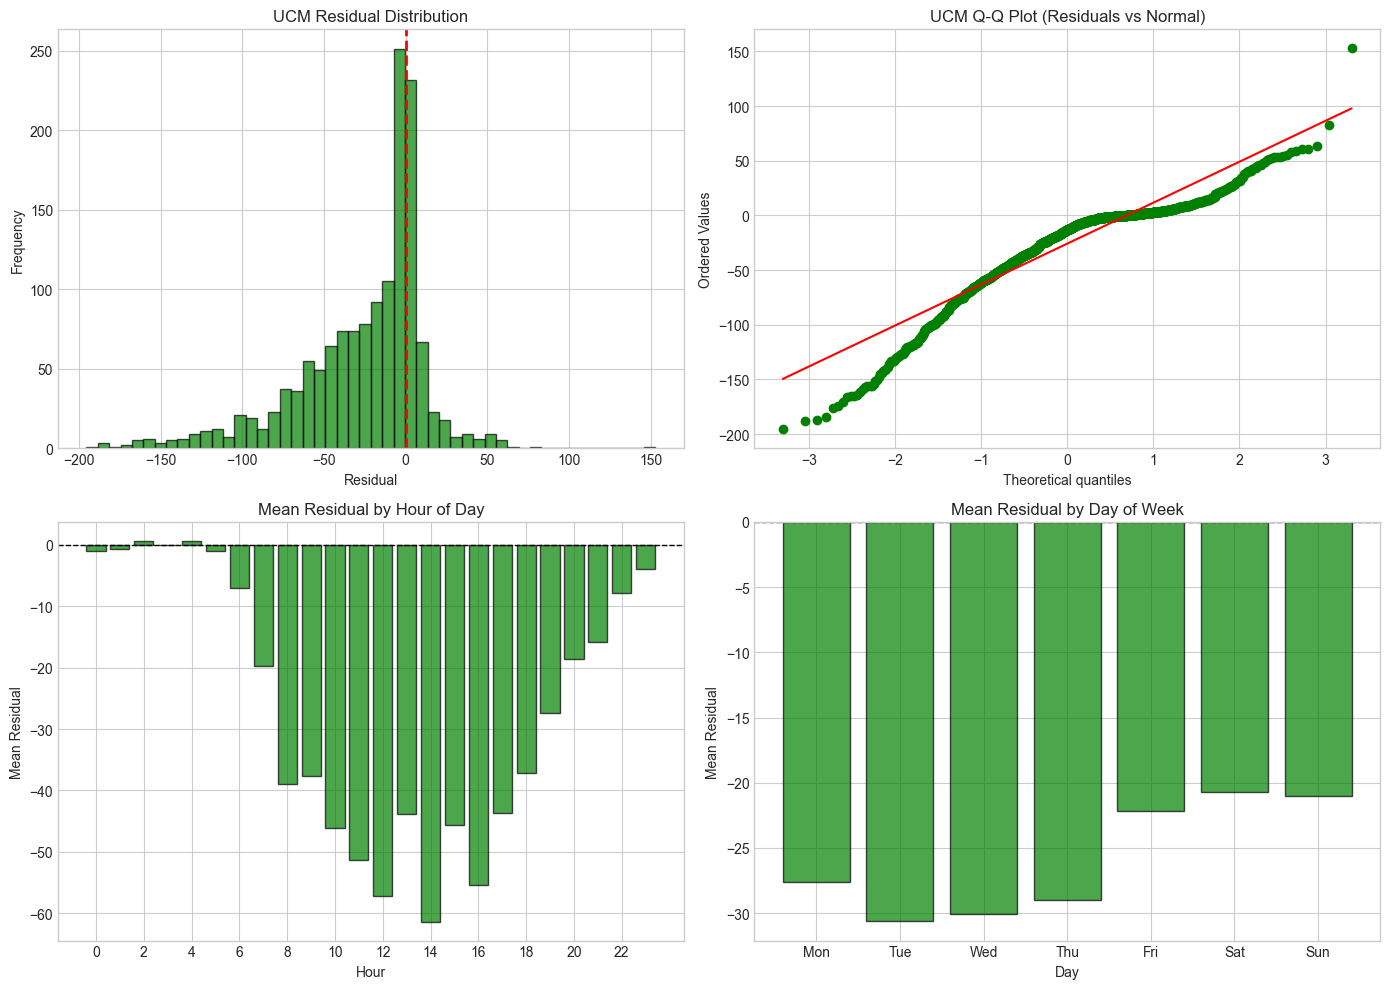

In [13]:
# =============================================================================
# UCM MODEL - PART 6: VALIDATION VISUALIZATION
# =============================================================================

fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# Plot 1: Full validation forecast vs actual
ax1 = axes[0]
ax1.plot(ucm_val_forecast_df.index, ucm_val_forecast_df['actual'], 
         label='Actual', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(ucm_val_forecast_df.index, ucm_val_forecast_df['forecast'], 
         label='UCM Forecast', alpha=0.7, linewidth=0.8, color='green')
ax1.set_title('UCM Validation: Full 60-Day Forecast vs Actual', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: First week zoom
first_week_ucm = ucm_val_forecast_df.iloc[:168]
ax2 = axes[1]
ax2.plot(first_week_ucm.index, first_week_ucm['actual'], 
         label='Actual', alpha=0.8, linewidth=1.5, color='blue')
ax2.plot(first_week_ucm.index, first_week_ucm['forecast'], 
         label='UCM Forecast', alpha=0.8, linewidth=1, color='green')
ax2.set_title('UCM Validation: First Week (168 hours)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Residuals
residuals_ucm = ucm_val_forecast_df['actual'] - ucm_val_forecast_df['forecast']
ax3 = axes[2]
ax3.plot(ucm_val_forecast_df.index, residuals_ucm, alpha=0.7, 
         linewidth=0.5, color='green', label='UCM Residuals')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.fill_between(ucm_val_forecast_df.index, residuals_ucm, 0, alpha=0.3, color='green')
ax3.set_title('UCM Residuals (Actual - Forecast)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Residual')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Residual diagnostics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# UCM Residual histogram
ax1 = axes[0, 0]
ax1.hist(residuals_ucm, bins=50, edgecolor='black', alpha=0.7, color='green')
ax1.axvline(x=0, color='red', linestyle='--', linewidth=2)
ax1.set_title('UCM Residual Distribution')
ax1.set_xlabel('Residual')
ax1.set_ylabel('Frequency')

# UCM Residual QQ plot
from scipy import stats
ax2 = axes[0, 1]
stats.probplot(residuals_ucm, dist="norm", plot=ax2)
ax2.set_title('UCM Q-Q Plot (Residuals vs Normal)')
ax2.get_lines()[0].set_color('green')
ax2.get_lines()[1].set_color('red')

# Residuals by hour of day
ucm_val_forecast_df['hour'] = ucm_val_forecast_df.index.hour
hourly_residuals_ucm = ucm_val_forecast_df.groupby('hour').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
ax3 = axes[1, 0]
ax3.bar(hourly_residuals_ucm.index, hourly_residuals_ucm.values, 
        color='green', alpha=0.7, edgecolor='black')
ax3.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax3.set_title('Mean Residual by Hour of Day')
ax3.set_xlabel('Hour')
ax3.set_ylabel('Mean Residual')
ax3.set_xticks(range(0, 24, 2))

# Residuals by day of week
ucm_val_forecast_df['dayofweek'] = ucm_val_forecast_df.index.dayofweek
daily_residuals_ucm = ucm_val_forecast_df.groupby('dayofweek').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
ax4 = axes[1, 1]
ax4.bar(range(7), daily_residuals_ucm.values, 
        color='green', alpha=0.7, edgecolor='black')
ax4.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax4.set_title('Mean Residual by Day of Week')
ax4.set_xlabel('Day')
ax4.set_ylabel('Mean Residual')
ax4.set_xticks(range(7))
ax4.set_xticklabels(day_names)

plt.tight_layout()
plt.show()


UCM COMPONENT DECOMPOSITION


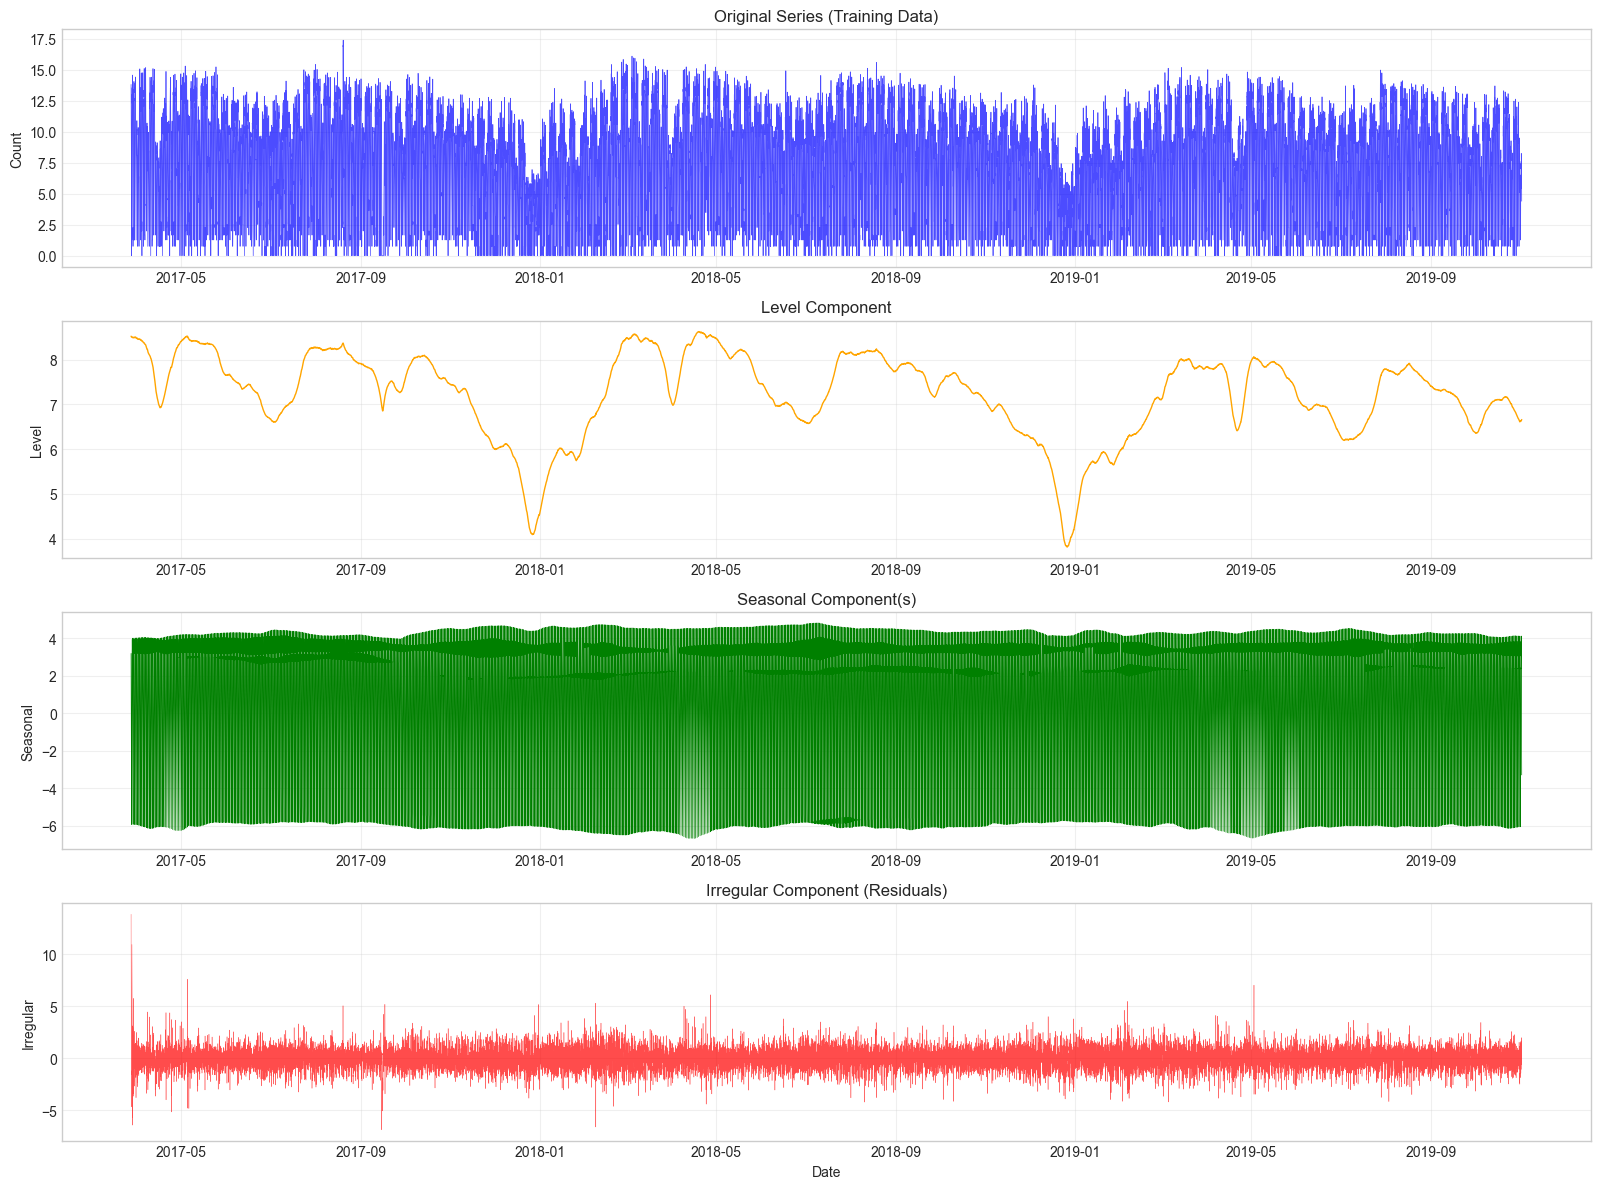


Component Statistics:
------------------------------------------------------------
Level - Mean: 7.22, Std: 0.93
Level - Range: [3.82, 8.62]

Seasonal - Mean: -0.00, Std: 3.49
Seasonal - Range: [-6.67, 4.81]

Irregular - Mean: -0.00, Std: 0.98
Irregular - Range: [-6.85, 13.82]
------------------------------------------------------------


In [14]:
# =============================================================================
# UCM MODEL - PART 7: COMPONENT DECOMPOSITION
# =============================================================================

# Extract fitted components from the best model
print("\n" + "=" * 80)
print("UCM COMPONENT DECOMPOSITION")
print("=" * 80)

# Plot components
fig, axes = plt.subplots(4, 1, figsize=(16, 12))

# Plot 1: Original series
ax1 = axes[0]
ax1.plot(train.index, y_train, alpha=0.7, linewidth=0.5, color='blue')
ax1.set_title('Original Series (Training Data)', fontsize=12)
ax1.set_ylabel('Count')
ax1.grid(True, alpha=0.3)

# Plot 2: Level component
ax2 = axes[1]
level_component = best_ucm_model.level.smoothed
ax2.plot(train.index, level_component, color='orange', linewidth=1)
ax2.set_title('Level Component', fontsize=12)
ax2.set_ylabel('Level')
ax2.grid(True, alpha=0.3)

# Plot 3: Seasonal component (if available)
ax3 = axes[2]
if hasattr(best_ucm_model, 'seasonal'):
    seasonal_component = best_ucm_model.seasonal.smoothed
    # Sum all seasonal components if multiple
    if seasonal_component.ndim > 1:
        seasonal_sum = seasonal_component.sum(axis=1)
    else:
        seasonal_sum = seasonal_component
    ax3.plot(train.index, seasonal_sum, color='green', linewidth=0.5)
    ax3.set_title('Seasonal Component(s)', fontsize=12)
else:
    ax3.text(0.5, 0.5, 'No seasonal component', ha='center', va='center', 
             transform=ax3.transAxes, fontsize=12)
ax3.set_ylabel('Seasonal')
ax3.grid(True, alpha=0.3)

# Plot 4: Irregular component
ax4 = axes[3]
irregular_component = best_ucm_model.resid  # Use .resid instead of .irregular
ax4.plot(train.index, irregular_component, color='red', linewidth=0.3, alpha=0.7)
ax4.set_title('Irregular Component (Residuals)', fontsize=12)
ax4.set_ylabel('Irregular')
ax4.set_xlabel('Date')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show statistics of components
print("\nComponent Statistics:")
print("-" * 60)
print(f"Level - Mean: {level_component.mean():.2f}, Std: {level_component.std():.2f}")
print(f"Level - Range: [{level_component.min():.2f}, {level_component.max():.2f}]")
if hasattr(best_ucm_model, 'seasonal'):
    print(f"\nSeasonal - Mean: {seasonal_sum.mean():.2f}, Std: {seasonal_sum.std():.2f}")
    print(f"Seasonal - Range: [{seasonal_sum.min():.2f}, {seasonal_sum.max():.2f}]")
print(f"\nIrregular - Mean: {irregular_component.mean():.2f}, Std: {irregular_component.std():.2f}")
print(f"Irregular - Range: [{irregular_component.min():.2f}, {irregular_component.max():.2f}]")
print("-" * 60)

In [15]:
# =============================================================================
# UCM MODEL - PART 8: RETRAIN ON FULL DATA & FINAL FORECAST
# =============================================================================

print("\n" + "=" * 80)
print("RETRAINING UCM ON FULL DATA")
print("=" * 80)

# Combine train and validation
y_full = pd.concat([train, validation])['value']

# APPLY BOX-COX IF IT WAS USED BEFORE
if 'lam' in locals() and 'offset' in locals():
    print(f"Applying Box-Cox to full dataset with lambda={lam:.4f}")
    y_full_shifted = y_full + offset
    # Use the same lambda as found in training for consistency
    y_full_transformed = boxcox(y_full_shifted, lmbda=lam)
    y_full = pd.Series(y_full_transformed, index=y_full.index)

print(f"Full training data: {len(y_full)} observations")
print(f"Date range: {y_full.index.min()} to {y_full.index.max()}")

# Use the best specification found
best_spec = best_ucm['spec']

# Fit final UCM model
print(f"\nFitting {best_ucm_name} on full data...")
final_ucm_model = UnobservedComponents(
    y_full,
    level=best_spec['level'],
    trend=best_spec['trend'],
    seasonal=best_spec['seasonal'],
    freq_seasonal=best_spec['freq_seasonal'],
    cycle=best_spec['cycle'],
    autoregressive=best_spec['autoregressive'],
    irregular=best_spec['irregular']
)

final_ucm_fit = final_ucm_model.fit(disp=False, maxiter=200)

print("✓ Model fitted successfully")
print(f"\nFinal Model Summary:")
print(f"  AIC: {final_ucm_fit.aic:,.2f}")
print(f"  BIC: {final_ucm_fit.bic:,.2f}")
print(f"  Log Likelihood: {final_ucm_fit.llf:,.2f}")

# Generate forecast for test period
print(f"\nGenerating {FORECAST_HORIZON}-hour forecast for test period...")

try:
    # Get prediction results with standard errors
    forecast_result = final_ucm_fit.get_forecast(steps=FORECAST_HORIZON)
    ucm_forecast_mean = forecast_result.predicted_mean
    ucm_forecast_ci = forecast_result.conf_int(alpha=0.05)
    
    # INVERSE BOX-COX TRANSFORM IF APPLIED
    if 'lam' in locals() and 'offset' in locals():
        print(f"Inverse transforming final forecast using lambda={lam:.4f}")
        ucm_forecast_mean = inverse_boxcox(ucm_forecast_mean, lam, offset)
        ucm_forecast_ci = inverse_boxcox(ucm_forecast_ci, lam, offset)
    
    has_ci = True
    print("✓ Forecast with 95% confidence intervals generated")
except:
    # Fallback if confidence intervals not available
    ucm_forecast_mean = final_ucm_fit.forecast(steps=FORECAST_HORIZON)
    
    # INVERSE BOX-COX TRANSFORM IF APPLIED
    if 'lam' in locals() and 'offset' in locals():
        print(f"Inverse transforming final forecast using lambda={lam:.4f}")
        ucm_forecast_mean = inverse_boxcox(ucm_forecast_mean, lam, offset)
        
    has_ci = False
    print("✓ Forecast generated (confidence intervals not available for this specification)")

# Create future dates
# Depending on transformation, y_full might be transformed, so index is preserved
last_date = y_full.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON,
    freq='H'
)

print(f"\nForecast period: {future_dates.min()} to {future_dates.max()}")

# Create forecast DataFrame
if has_ci:
    ucm_final_forecast_df = pd.DataFrame({
        'date': future_dates,
        'forecast': ucm_forecast_mean.values,
        'lower_ci': ucm_forecast_ci.iloc[:, 0].values,
        'upper_ci': ucm_forecast_ci.iloc[:, 1].values
    }).set_index('date')
else:
    ucm_final_forecast_df = pd.DataFrame({
        'date': future_dates,
        'forecast': ucm_forecast_mean.values
    }).set_index('date')

# Clip negative forecasts to 0
ucm_final_forecast_df['forecast'] = ucm_final_forecast_df['forecast'].clip(lower=0)
if has_ci:
    ucm_final_forecast_df['lower_ci'] = ucm_final_forecast_df['lower_ci'].clip(lower=0)
    ucm_final_forecast_df['upper_ci'] = ucm_final_forecast_df['upper_ci'].clip(lower=0)

print("\nForecast Summary Statistics:")
print(ucm_final_forecast_df.describe())


RETRAINING UCM ON FULL DATA
Applying Box-Cox to full dataset with lambda=0.2567
Full training data: 24222 observations
Date range: 2017-03-27 18:00:01 to 2019-12-31 23:00:01

Fitting UCM-3: Local Level + Seasonal(24h) + AR(1) on full data...
✓ Model fitted successfully

Final Model Summary:
  AIC: 66,578.84
  BIC: 66,627.40
  Log Likelihood: -33,283.42

Generating 1440-hour forecast for test period...
Inverse transforming final forecast using lambda=0.2567
✓ Forecast with 95% confidence intervals generated

Forecast period: 2020-01-01 00:00:01 to 2020-02-29 23:00:01

Forecast Summary Statistics:
          forecast     lower_ci     upper_ci
count  1431.000000  1121.000000  1440.000000
mean     21.178671     4.500782    74.174396
std      21.142556     5.045268    62.215872
min       0.000000     0.000000     0.000000
25%       0.338079     0.000000    12.104364
50%      15.757457     2.616602    66.734656
75%      36.922132     7.932958   126.409675
max      64.443687    21.163216   21

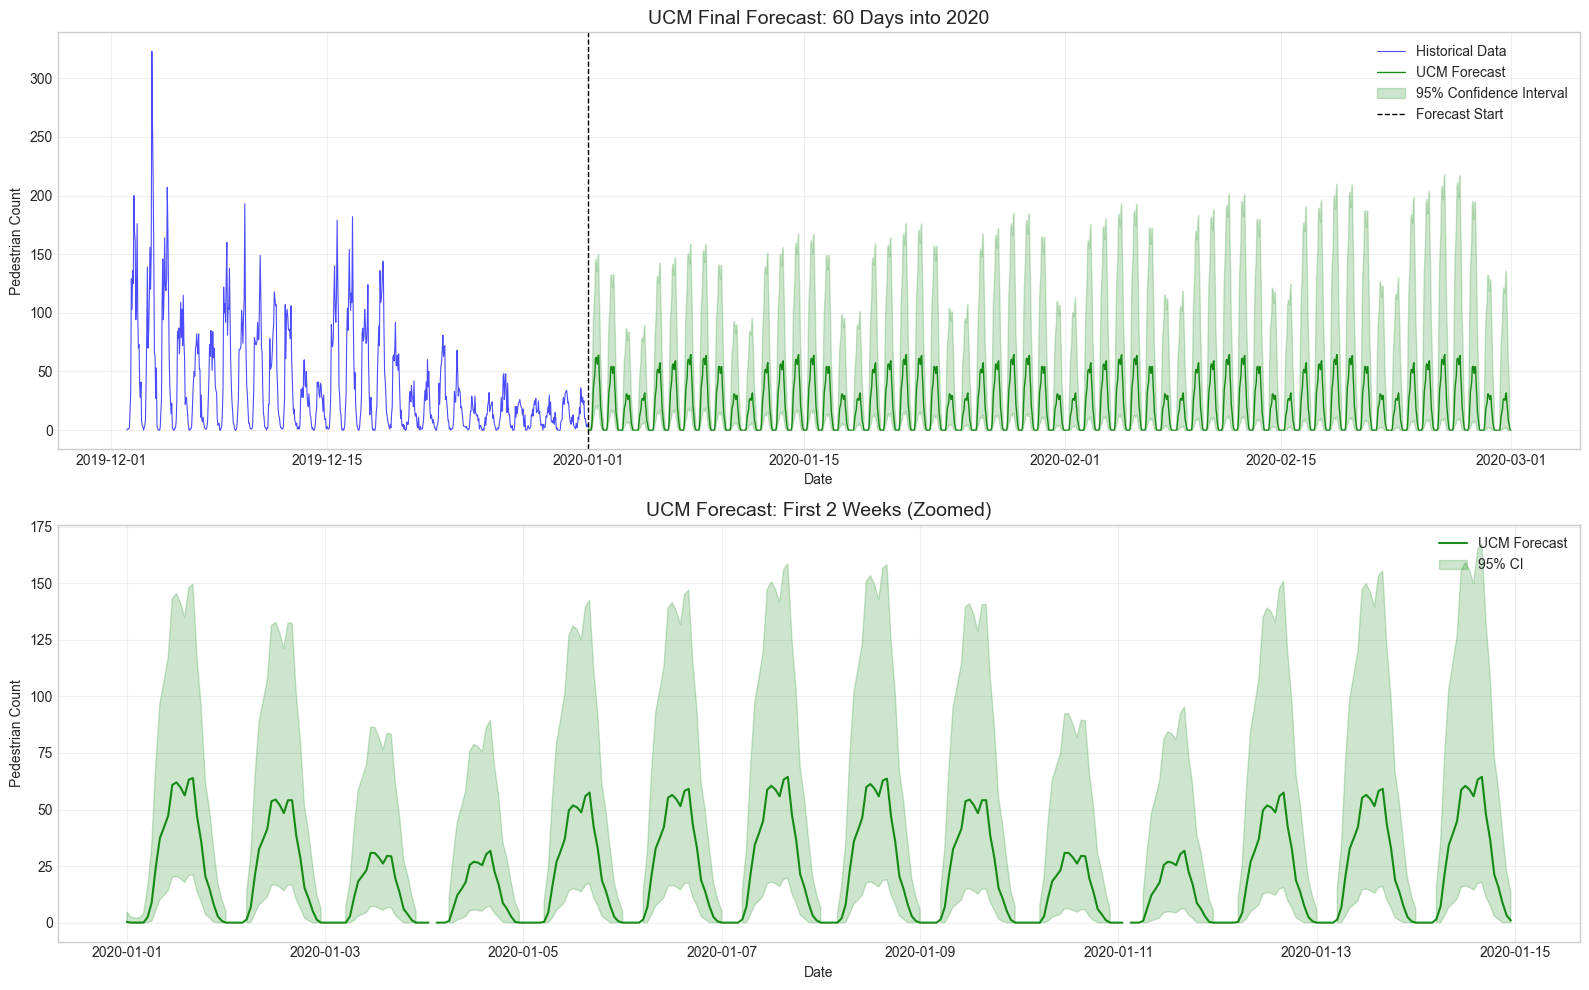

In [17]:
# =============================================================================
# UCM MODEL - PART 9: FINAL FORECAST VISUALIZATION
# =============================================================================

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: Historical data + UCM Forecast
ax1 = axes[0]

# Last 30 days of training data for context
# Use original values for visualization (inverse transform if needed)
context_data = y_full.iloc[-720:].copy()

if 'lam' in locals() and 'offset' in locals():
    # If variables exist, y_full is likely transformed, so we inverse transform for plotting
    context_values = inverse_boxcox(context_data.values, lam, offset)
    context_data = pd.Series(context_values, index=context_data.index)

ax1.plot(context_data.index, context_data.values, 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(ucm_final_forecast_df.index, ucm_final_forecast_df['forecast'], 
         label='UCM Forecast', alpha=0.9, linewidth=1, color='green')

if has_ci:
    ax1.fill_between(ucm_final_forecast_df.index, 
                      ucm_final_forecast_df['lower_ci'], 
                      ucm_final_forecast_df['upper_ci'],
                      alpha=0.2, color='green', label='95% Confidence Interval')

ax1.axvline(x=y_full.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax1.set_title('UCM Final Forecast: 60 Days into 2020', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Plot 2: First 2 weeks of forecast (zoomed)
first_two_weeks_ucm = ucm_final_forecast_df.iloc[:336]
ax2 = axes[1]
ax2.plot(first_two_weeks_ucm.index, first_two_weeks_ucm['forecast'], 
         label='UCM Forecast', alpha=0.9, linewidth=1.5, color='green')

if has_ci:
    ax2.fill_between(first_two_weeks_ucm.index, 
                      first_two_weeks_ucm['lower_ci'], 
                      first_two_weeks_ucm['upper_ci'],
                      alpha=0.2, color='green', label='95% CI')

ax2.set_title('UCM Forecast: First 2 Weeks (Zoomed)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()